<img src="https://ga-curriculum.github.io/universal-resources-internal/ga-logos/ga-red-cog-72x72.png" alt="" style="float: left; margin: 20px 20px 0 0; height: 55px">

# Intro to Unsupervised Learning with K-Means Clustering

Revised by Jeff Hale

### Learning Objectives
*After this lesson, you will be able to:*
- Explain the difference between supervised and unsupervised learning
- Understand when to use clustering
- Format and preprocess data for clustering
- Perform a K-Means clustering analysis
- Evaluate K-Means clusters on Silhouette Score and Inertia

## New Issues with Unsupervised Learning
Since there is no Y variable to "supervise" our learning, unsupervised learning presents us with some new issues we've never had to work through:

* **What is "correct"?** Since there's no Y variable, we don't have an easy to way know if we're even doing a good job.
* **Tuning parameter selection.** Many unsupervised models have tuning parameters. How do we tune them if we don't know how to evaluate our model?
* **Unpredictability (clustering).** In clustering, it is very difficult to predict what our model will give us. It's possible that a clustering algorithm won't give us actionable results. More on this later.

<a name="intro"></a>
# Introduction to Clustering

---

**Clustering** is a task in which we seek to group our observations in **homogenous clusters**. Since it's unsupervised, it is up to us, the data scientists, to decide what we mean by "homogenous".

<a name="algos"></a>
# Clustering algorithms 

---

The are many different algorithms that can perform clustering given a dataset. 

These algorithms nearly always reduce to difficult optimization problems which may converge on a local minimum (similarly to gradient descent).

- **K-Means** (mean centroids)
- **DBSCAN** (density based)
- **Hierarchical** (nested clusters by merging or splitting successively)
- **Affinity Propagation** (graph based approach to let points 'vote' on their preferred 'exemplar')
- **Mean Shift** (can find number of clusters)
- **Spectral Clustering**
- **Agglomerative Clustering** (suite of algorithms all based on applying the same criteria/characteristics of one cluster to others)


Image from scikit-learn: ["Comparing different clustering algorithms on toy datasets."](https://scikit-learn.org/stable/auto_examples/cluster/plot_cluster_comparison.html)

![](./assets/imgs/sklearn-clustering.png)

From the above, note that $k$-Means clustering:
- is really fast!
- can only create convex clusters. This implies that its clusters can always be linearly separated.
- may have to be run multiple times to get the best clusters.

> - "We argue that there are many clustering algorithms, because the notion of "cluster" cannot be precisely defined."<br>
> - "Therefore, comparing clustering algorithms, must take into account a careful understanding of the inductive principles involved."<br>
> - "The nature of clustering is exploratory, rather than confirmatory."
>
> From: Vladimir Estivill-Castro. ["Why so many clustering algorithms -- A Position Paper" (PDF)](https://citeseerx.ist.psu.edu/document?repid=rep1&type=pdf&doi=abaa7e9508dee86113d487987345df73315767a9)

Today we're going to look only at one of the algorithms: **k-means**.

<a id='k-means'></a>
# K-Means clustering

---

#### K-Means is the most popular clustering algorithm

K-means is one of the easier methods to understand and other clustering techniques use some of the same assumptions that k-means relies on.

- **k** is the number of clusters.
- **Means** refers to the mean points of the k clusters.

![](../assets/imgs/sklearn-kmeans-voronoi.png)

Image from scikit-learn: ["A demo of K-Means clustering on the handwritten digits data"](https://scikit-learn.org/stable/auto_examples/cluster/plot_kmeans_digits.html).

**You must choose $k$, the number of clusters, in advance.** Note that this is a huge issue, since we rarely have an intuition for this number. And since we're in unsupervised territory, it's hard for us to know if we've picked correctly! We'll talk about how to pick $k$ later.

The algorithm takes your entire dataset and iterates over its features and observations to determine clusters based around center points. These center points are known as **centroids**.

<a id='choose-k'></a>
## Choosing $k$
This still remains an open question. After all, we're tuning a tuning parameter with no metric for success! Here are three ideas:

* Make an educated guess
    - Industry knowledge (there are five kinds of Democrats...)
    - Visualization (probably impossible if you have more than 2 variables)
* Judge based on a pseudo-evaluation metric, like the **silhouette score**.
* If you're using the resulting cluster labels as input to a supervised learning method later, you can tune $k$ to have the best supervised learning model. More on **transfer learning** later.

<a id='converge'></a>
## A Note on K-Means Convergence

---

**Knowing your domain and dataset is essential. Evaluating the clusters visually is a must (if possible).**

> _"Given enough time, k-means will always converge, however this may be to a local minimum. This is highly dependent on the initialization of the centroids. As a result, the computation is often done several times, with different initializations of the centroids. One method to help address this issue is the k-means++ initialization scheme, which has been implemented in scikit-learn (use the init='kmeans++' parameter). This initializes the centroids to be (generally) distant from each other, leading to provably better results than random initialization, as shown in the reference."_ [sklearn Clustering Guide](http://scikit-learn.org/stable/modules/clustering.html#k-means)

<a name="sklearn"></a>
# K-Means in sklearn

---

Below we will implement K-Means using sklearn. We'll use simulated data.

In [1]:
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

import numpy as np
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib

matplotlib.style.use('ggplot')

# Let's make some blobs to test K-Means on
data, color = make_blobs(n_samples=100, random_state=42, centers=3, cluster_std=1.5)

df = pd.DataFrame(data, columns=["x1", "x2"])
df.head()

,x1,x2
0,-8.149818,-9.152380
1,5.860155,0.126873
2,-3.213409,9.828126
3,6.744070,-0.129607
4,-6.342946,-6.038933


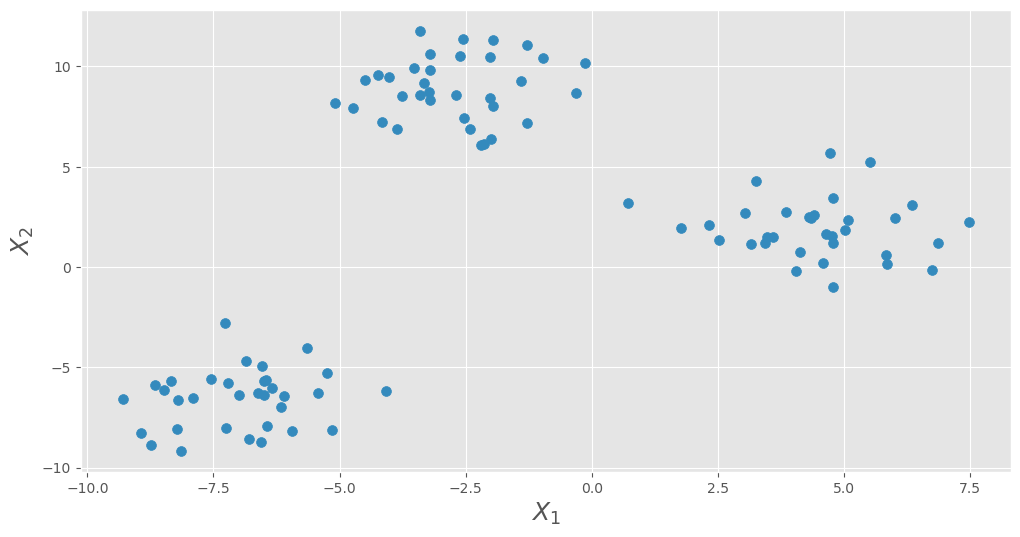

In [2]:
# Take a look at the data using a scatterplot
df.plot(kind="scatter", x="x1", y="x2", figsize=(12,6), s=50)
plt.xlabel("$X_1$", fontsize=18)
plt.ylabel("$X_2$", fontsize=18);

In [3]:
# Define X
X = df[['x1', 'x2']]

In [4]:
# There's a VERY important step before fitting our K-Means Model. Any ideas?
sc = StandardScaler()
X_scaled = sc.fit_transform(X)

In [5]:
# Fit a K-means clustering model
km = KMeans(n_clusters=3, random_state=42)
km.fit(X_scaled)

/Users/mattbrems/anaconda3/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


KMeans(n_clusters=3, random_state=42)

## What did we discover?

### I. Cluster Predictions

In [6]:
# Option 1: Class attribute

km.labels_

array([1, 2, 0, 2, 1, 2, 0, 2, 2, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1,
       1, 0, 0, 0, 2, 1, 1, 1, 1, 2, 2, 1, 0, 0, 0, 0, 2, 2, 1, 0, 2, 0,
       0, 2, 1, 1, 1, 2, 2, 2, 0, 1, 1, 1, 0, 0, 2, 0, 1, 2, 1, 2, 1, 1,
       2, 1, 2, 2, 2, 1, 1, 0, 2, 1, 2, 1, 2, 2, 0, 2, 0, 1, 0, 0, 0, 2,
       0, 2, 2, 2, 0, 2, 0, 0, 0, 2, 1, 0], dtype=int32)

In [7]:
# Option 2: Predict

km.predict(X_scaled)

array([1, 2, 0, 2, 1, 2, 0, 2, 2, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1,
       1, 0, 0, 0, 2, 1, 1, 1, 1, 2, 2, 1, 0, 0, 0, 0, 2, 2, 1, 0, 2, 0,
       0, 2, 1, 1, 1, 2, 2, 2, 0, 1, 1, 1, 0, 0, 2, 0, 1, 2, 1, 2, 1, 1,
       2, 1, 2, 2, 2, 1, 1, 0, 2, 1, 2, 1, 2, 2, 0, 2, 0, 1, 0, 0, 0, 2,
       0, 2, 2, 2, 0, 2, 0, 0, 0, 2, 1, 0], dtype=int32)

In [8]:
# Attach predicted cluster to original points

df['cluster'] = km.labels_
df.head()

,x1,x2,cluster
0,-8.149818,-9.152380,1
1,5.860155,0.126873,2
2,-3.213409,9.828126,0
3,6.744070,-0.129607,2
4,-6.342946,-6.038933,1


### II. Centroids

In [9]:
# Option 1: Using groupby

df.groupby('cluster').mean()

,x1,x2
cluster,,
0,-2.747107,8.896498
1,-6.987751,-6.574270
2,4.429326,1.921795


In [10]:
# Option 2: (Preferred method) Using cluster_centers_

km.cluster_centers_

# But wait... why does this not match the one above?!

array([[-0.19912024,  1.13805994],
       [-1.07070258, -1.23896837],
       [ 1.27585677,  0.06642177]])

In [11]:
# Remember, we scaled this! We need to "unscale".

centroids = sc.inverse_transform(km.cluster_centers_)

## Visually Verifying Cluster Labels

In [12]:
# Create Centroid DataFrame
centroids = pd.DataFrame(
    centroids,
    columns=["x1", "x2"]
)
centroids

,x1,x2
0,-2.747107,8.896498
1,-6.987751,-6.574270
2,4.429326,1.921795


<Figure size 1000x800 with 0 Axes>

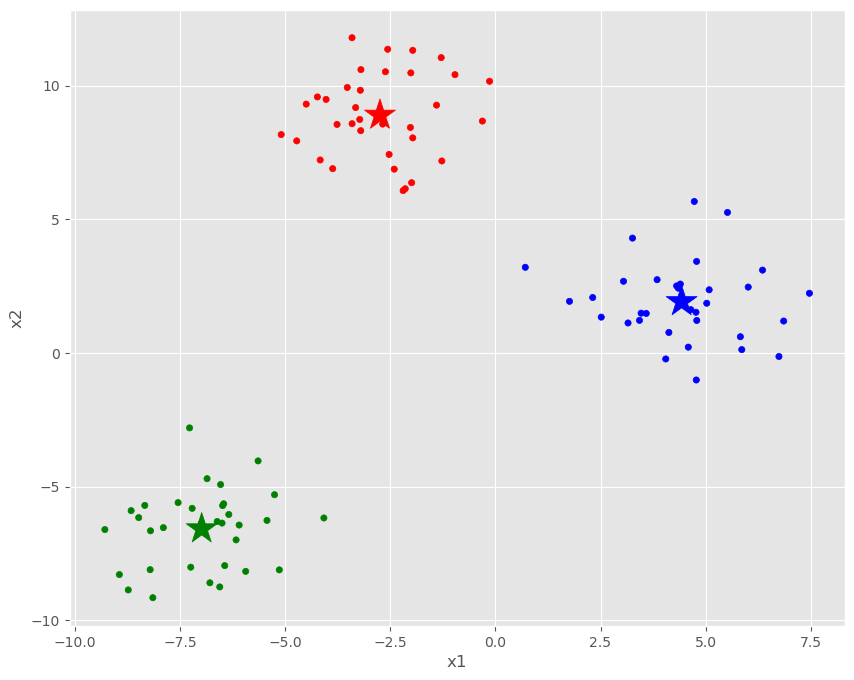

In [13]:
# Create Scatterplot!

# Figsize
plt.figure(figsize=(10,8))

# Map colors for different clusters
colors = ["red", "green", "blue"]
df['color'] = df['cluster'].map(lambda p: colors[p])

# Plot points
ax = df.plot(    
    kind="scatter", 
    x="x1", y="x2",
    figsize=(10,8),
    c = df['color']
)

# Plot Centroids
centroids.plot(
    kind="scatter", 
    x="x1", y="x2", 
    marker="*", c=["r", "g", "b"], s=550, ax=ax
);


---
## Metrics for Assessing Clusters

### Inertia: how dense is each cluster?

Inertia is the sum of squared distance between each observation in a cluster and the centroid of that cluster, summed over each cluster.

$$ \sum_{j=0}^{k}\sum_{i\in C_j}^{n} (\text{obs}_i - \mu_j)^2 $$

`.inertia_` is an attribute of a fitted sklearn's kmeans object.

The K-means algorithm seeks to minimize the inertia across its clusters.
- Inertia can range from 0 to infinity.
- The lower, the better.
- When would inertia equal 0?

#### Get the inertia

In [14]:
km.inertia_

12.264727255529843

---
### Silhouette Score

Tells you how much closer data points are to their own clusters than to the nearest neighbor cluster.

How far apart are the clusters?
- ranges from -1 to 1
- high silhouette score means the clusters are well separated



### $s_i = \frac{b_i - a_i}{max\{a_i, b_i\}}$

Where:
- $a_i$ = Cohesion: Mean distance of points within a cluster from each other.
- $b_i$ = Separation: Mean distance from point $x_i$ to all points in the next nearest cluster.

Use scikit-learn: `metrics.silhouette_score(X_scaled, labels)`.

#### Higher silhouette score is better!


#### Compute the silhouette score 

In [15]:
from sklearn.metrics import silhouette_score

In [16]:
silhouette_score(X_scaled, km.labels_)

0.7723797723428811

---
## How do I know which number to pick for $k$? 🤔

Finding the best $k$ to use for $k$-means clustering is not a simple task.
  

NO ground truth, so there isn't necessarily a "correct" number of clusters. 

The business application is often an important consideration:
   - e.g. I need to create 3 profiles for marketing to target
   - Even if the most natural-looking clusters are small, we may try to group several of them together so that it makes financial sense to target those groups.

**Other common approaches:**
- Previous experience.
- Using the elbow method to find a number of clusters that no longer seems to improve a clustering metric by a noticeable degree.
- Scatter plots show separable clusters
- The silhouette score 
- Inertia
- If we're using clustering to improve performance on a supervised learning problem, then we can use our usual methods to test predictions and tune $k$.

---
### Use the elbow method to choose _k_

The [elbow method](https://en.wikipedia.org/wiki/Elbow_method_(clustering)) is one possible method to help narrow in on the ideal value of **K**. 

### Choose the number of clusters where the next cluster doesn't significantly improve performance. 

#### Let's use the .inertia_ method as our evaluation metric

In [17]:
inertia_list = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    inertia_list.append(kmeans.inertia_)
    
inertia_list

/Users/mattbrems/anaconda3/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/Users/mattbrems/anaconda3/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/Users/mattbrems/anaconda3/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/Users/mattbrems/anaconda3/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` wi

[200.00000000000003,
 67.9287466927128,
 12.264727255529845,
 10.45393252210196,
 8.873308417484704,
 7.277037299399019,
 6.362431451324463,
 5.4782832092367455,
 4.806662102692635,
 4.267265452206031]

#### Analyze the above

- Do you see the **"elbow"**?

- What's the best value for _k_?



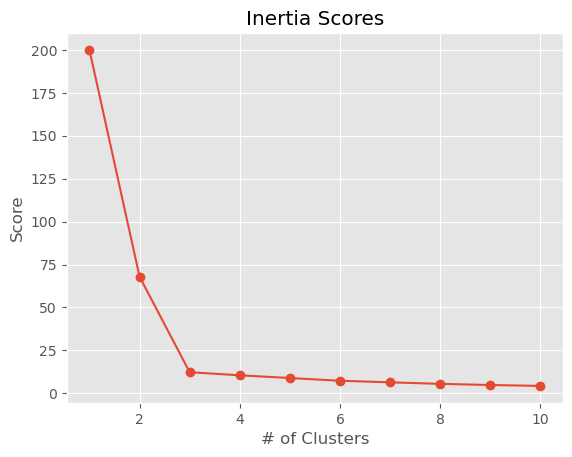

In [18]:
plt.plot(range(1, 11), inertia_list, marker='o')
plt.xlabel('# of Clusters')
plt.ylabel('Score')
plt.title('Inertia Scores');

#### Now let's make a plot with the silhouette score

In [19]:
silhouette_list = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    silhouette_list.append(silhouette_score(X_scaled, kmeans.labels_))
silhouette_list

/Users/mattbrems/anaconda3/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/Users/mattbrems/anaconda3/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/Users/mattbrems/anaconda3/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/Users/mattbrems/anaconda3/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` wi

[0.6461767583224244,
 0.7723797723428811,
 0.6197660988611052,
 0.5047092466603167,
 0.3551790693857368,
 0.3605137551499765,
 0.3582798476535438,
 0.3763374498397031,
 0.3585789063702689]

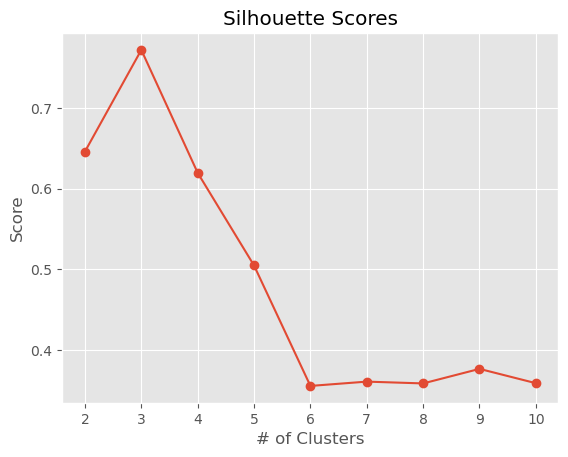

In [20]:
plt.plot(range(2, 11), silhouette_list, marker='o')
plt.xlabel('# of Clusters')
plt.ylabel('Score')
plt.title('Silhouette Scores');

#### What _k_ should we choose?

3!

# Bonus Exercise 🏋️‍♂️🏋️‍♀️ : Old Faithful
The classic Old Faithful dataset describes the durations of eruptions and the amount of waiting time since the last eruption for the Old Faithful geyser. Plot this data. Do you think this data could benefit from clustering? How many clusters are there?

In [21]:
df = pd.read_csv("./assets/datasets/geyser.csv")
df.head()

,duration,waiting
0,3.600,79
1,1.800,54
2,3.333,74
3,2.283,62
4,4.533,85


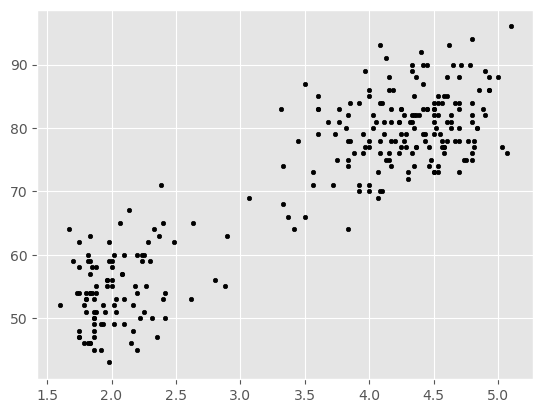

In [22]:
plt.scatter(df['duration'], df['waiting'], c="black", s=10);

In [23]:
# Define X
X = df[['duration', 'waiting']]

In [24]:
# There's a VERY important step before fitting our K-Means Model. Any ideas?
sc = StandardScaler()
X_scaled = sc.fit_transform(X)

In [25]:
# Fit a K-means clustering model
km = KMeans(n_clusters=2, random_state=42)
km.fit(X_scaled)

/Users/mattbrems/anaconda3/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


KMeans(n_clusters=2, random_state=42)

In [26]:
df['cluster'] = km.labels_
df.head()

,duration,waiting,cluster
0,3.600,79,0
1,1.800,54,1
2,3.333,74,0
3,2.283,62,1
4,4.533,85,0


In [27]:
# Create Centroid DataFrame
centroids = pd.DataFrame(
    sc.inverse_transform(km.cluster_centers_),
    columns=["duration", "waiting"]
)
centroids

,duration,waiting
0,4.296328,80.080460
1,2.052204,54.591837


<Figure size 1000x800 with 0 Axes>

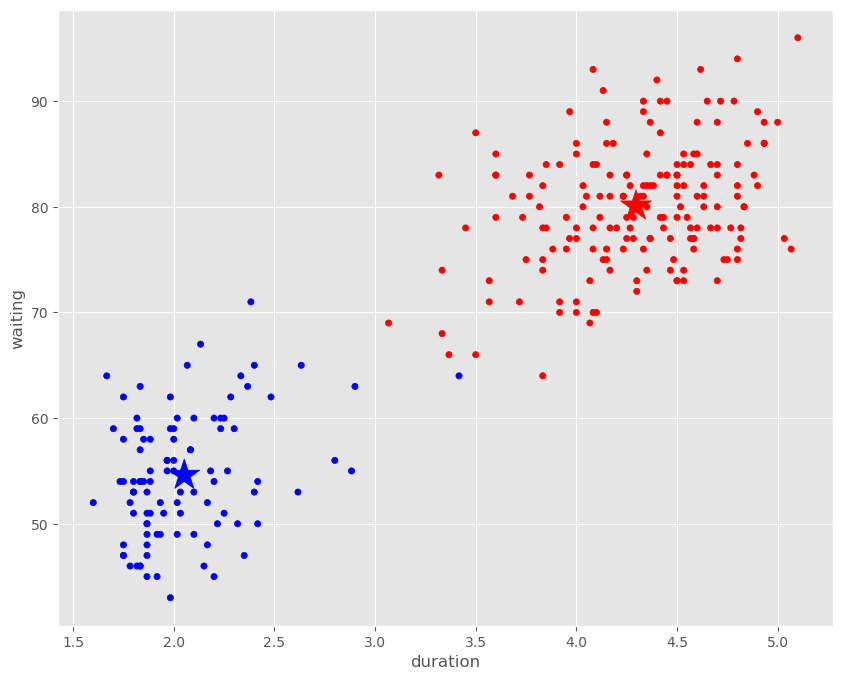

In [28]:
# Create Scatterplot!

# Figsize
plt.figure(figsize=(10,8))

# Map colors for different clusters
colors = ["red", "blue"]
df['color'] = df['cluster'].map(lambda p: colors[p])

# Plot points
ax = df.plot(    
    kind="scatter", 
    x="duration", y="waiting",
    figsize=(10,8),
    c = df['color']
)

# Plot Centroids
centroids.plot(
    kind="scatter", 
    x="duration", y="waiting", 
    marker="*", c=["r", "b"], s=550, ax=ax
);

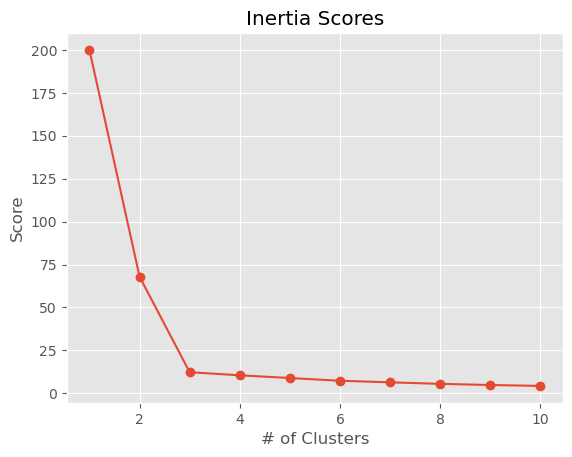

In [29]:
plt.plot(range(1, 11), inertia_list, marker='o')
plt.xlabel('# of Clusters')
plt.ylabel('Score')
plt.title('Inertia Scores');

In [30]:
silhouette_list = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    silhouette_list.append(silhouette_score(X_scaled, kmeans.labels_))
silhouette_list

/Users/mattbrems/anaconda3/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/Users/mattbrems/anaconda3/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/Users/mattbrems/anaconda3/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/Users/mattbrems/anaconda3/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` wi

[0.7451774401188772,
 0.4850815668329722,
 0.38223485280121405,
 0.36281068125745164,
 0.39195723855368747,
 0.39152691138367,
 0.3583602892862309,
 0.35161802491917615,
 0.3511702058696223]

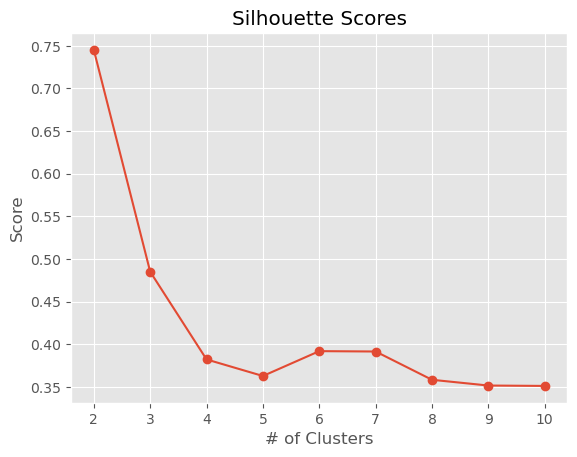

In [31]:
plt.plot(range(2, 11), silhouette_list, marker='o')
plt.xlabel('# of Clusters')
plt.ylabel('Score')
plt.title('Silhouette Scores');

### How many clusters should be used?

2!

---
<a id="lesson-summary"></a>
## Lesson Summary

Remember that different starting points may give you different clusters. ⚠️ You won't necessarily get an optimal set of clusters!    

You've learned about when and how to use the unsupervised learning clustering algorithm _k-means_. You saw how to save your cluster labels in a DataFrame. You learned several way to evaluate the best number of clusters. 

### Check for understanding

- What's the main difference between supervised learning and unsupervised learning
- Why use clustering?
- What does k-means clustering do?
- What does silhouette score measure?

## Further reading

- The [scikit-learn documentation](http://scikit-learn.org/stable/modules/clustering.html) has a great summary of many other clustering algorithms.
- This [PyData talk](https://www.youtube.com/watch?v=Mf6MqIS2ql4) is good overview of clustering, different algorithms, and how to think about the quality of your clusters.